# Exploring the Dash *et al* dataset

This data was generated in [Quantifiable predictive features define epitope specific T cell  receptor repertoires](https://doi.org/10.1038/nature22383) and further analysed in [Measures of epitope binding degeneracy from T cell receptor repertoires](https://www.pnas.org/doi/abs/10.1073/pnas.2213264120). In this notebook we explore the dataset and re-create some of the analysis done in other works.

In [1]:
import subprocess

import anarci
import logomaker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tidytcells
import umap
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from pyxdameraulevenshtein import damerau_levenshtein_distance
from sklearn.cluster import HDBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

from tcr_pmhc_predicted_structures.imgt_numbering import IMGT_CDR3

2026-02-05 14:35:56.624911: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
CLIP_DISTANCE = 5
MIN_CLUSTER_SIZE = 4

In [3]:
def plot_umap(umap: np.ndarray, clusters: np.ndarray, title: str | None = None, ax: Axes | None = None) -> Axes:
    clusters = clusters.copy()
    clusters[(clusters != 'None') & (clusters != 'Background')] = (
        'Cluster ' + clusters[(clusters != 'None') & (clusters != 'Background')]
    )

    ax = sns.scatterplot(
        x=umap[(clusters != 'None') & (clusters != 'Background'), 0],
        y=umap[(clusters != 'None') & (clusters != 'Background'), 1],
        hue=clusters[(clusters != 'None') & (clusters != 'Background')],
        alpha=0.65,
        ax=ax,
    )

    ax = sns.scatterplot(
        x=umap[clusters == 'None', 0],
        y=umap[clusters == 'None', 1],
        color='grey',
        alpha=0.55,
        label='None',
        ax=ax,
    )

    ax = sns.scatterplot(
        x=umap[clusters == 'Background', 0],
        y=umap[clusters == 'Background', 1],
        marker='x',
        color='black',
        alpha=0.55,
        label='Background',
        ax=ax,
    )

    ax.set_title(title)
    ax.legend(title='Cluster')

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    return ax


def align_sequences(sequences: list[str]) -> list[str]:
    child = subprocess.Popen(
        [
            '/usr/bin/env',
            'mafft-linsi',
            '--quiet',
            '--op',
            '2',
            '--ep',
            '10',
            '--amino',
            '-',
        ],
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
    )
    child.stdin.write('\n'.join(f'>{idx}\n{sequence}' for idx, sequence in enumerate(sequences)).encode())
    child_out = child.communicate()[0].decode('utf8')
    aligned_sequences = [line.strip() for line in child_out.split('\n') if line and not line.startswith('>')]
    child.stdin.close()

    return aligned_sequences


def make_logo_plot(cluster: pd.DataFrame) -> None:
    fig, axes = plt.subplots(2, 3, figsize=(10, 5), gridspec_kw={'width_ratios': (1, 5, 1), 'wspace': 0.1}, sharey=True)
    fig.suptitle(f'Cluster {cluster.name}')

    for chain_type, axes_row in zip(('a', 'b'), axes, strict=True):
        axes_row[0].set_ylabel({'a': 'Alpha Chain', 'b': 'Beta Chain'}[chain_type], fontsize=14)

        aligned_sequences = align_sequences(cluster[f'cdr3_{chain_type}_aa'])
        probs = logomaker.alignment_to_matrix(aligned_sequences, to_type='counts')

        logomaker.Logo(probs, color_scheme='chemistry', show_spines=False, baseline_width=0.0, ax=axes_row[1])

        axes_row[1].set_xticks([])
        axes_row[1].set_yticks([])

        counts_v = cluster[f'v_{chain_type}_gene'].value_counts()
        counts_j = cluster[f'j_{chain_type}_gene'].value_counts()

        for ax, counts in zip([axes_row[0], axes_row[2]], [counts_v, counts_j], strict=True):
            previous_count = 0
            for gene_name, cum_count in counts.cumsum().items():
                logomaker.Glyph(0.5, gene_name[3:], previous_count, cum_count, ax=ax)
                previous_count = cum_count

            ax.set_xticks([])
            ax.set_yticks([])
            ax.spines[:].set_visible(False)


def plot_sequence_distances(
    distance_matrix: np.ndarray,
    cluster_colours: np.ndarray,
    cluster_order: np.ndarray,
    cluster_counts: np.ndarray,
    new_order: np.ndarray,
    subject_colours: np.ndarray,
    epitope_colours: np.ndarray | None = None,
) -> tuple[Figure, np.ndarray[Axes]]:
    if epitope_colours is not None:
        fig, axes = plt.subplots(1, 4, gridspec_kw={'width_ratios': [1, 1, 1, 20]})

    else:
        fig, axes = plt.subplots(1, 3, gridspec_kw={'width_ratios': [1, 1, 20]})

    idx = 0

    axes[idx].imshow(subject_colours, aspect='auto')

    axes[idx].set_ylabel('Subject', fontsize=14)
    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    idx += 1

    if epitope_colours is not None:
        axes[idx].imshow(epitope_colours, aspect='auto')

        axes[idx].set_ylabel('Epitope', fontsize=14)
        axes[idx].set_xticks([])
        axes[idx].set_xticklabels('')
        axes[idx].set_yticks([])
        axes[idx].set_yticklabels('')

        idx += 1

    axes[idx].imshow(cluster_colours, aspect='auto')

    axes[idx].set_ylabel('Cluster', fontsize=14)
    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    accumulation = 0
    for cluster in cluster_order:
        cluster_size = cluster_counts[cluster]

        if cluster_size >= MIN_CLUSTER_SIZE:
            position = cluster_counts[cluster] // 2 + accumulation
            axes[idx].text(
                x=0.025,
                y=position,
                s=str(cluster),
                va='center',
                ha='center',
                fontsize=8,
            )

        accumulation += cluster_size

    idx += 1

    sns.heatmap(
        np.clip(distance_matrix[new_order, :][:, new_order], a_min=None, a_max=CLIP_DISTANCE),
        cmap='viridis_r',
        ax=axes[idx],
    )

    axes[idx].set_xlabel(r'CDR3$\alpha$', fontsize=14)
    axes[idx].set_ylabel(r'CDR3$\beta$', fontsize=14, rotation=270, labelpad=15)
    axes[idx].yaxis.set_label_position('right')

    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    cbar = axes[idx].collections[0].colorbar
    cbar.set_label('Sequence Levenshtein Distance', fontsize=14, rotation=270, labelpad=15)
    cbar.set_ticks(cbar.get_ticks())
    cbar.set_ticklabels(
        [f'{int(label)}' if label != CLIP_DISTANCE else f'>{CLIP_DISTANCE}' for label in cbar.get_ticks()]
    )

    fig.set_layout_engine('tight')

    return fig, axes


def calculate_distances(
    cdr_3_alpha_sequences: list[str], cdr_3_beta_sequences: list[str]
) -> tuple[np.ndarray, np.ndarray]:
    num_tcrs = len(cdr_3_alpha_sequences)

    cdr3_alpha_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)
    for j in range(num_tcrs - 1):
        for i in range(j + 1, num_tcrs):
            cdr3_alpha_distance_matrix[i, j] = damerau_levenshtein_distance(
                cdr_3_alpha_sequences[i], cdr_3_alpha_sequences[j]
            )

    cdr3_beta_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)
    for i in range(num_tcrs - 1):
        for j in range(i + 1, num_tcrs):
            cdr3_beta_distance_matrix[i, j] = damerau_levenshtein_distance(
                cdr_3_beta_sequences[i], cdr_3_beta_sequences[j]
            )

    distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_beta_distance_matrix], axis=0)

    cdr3_alpha_distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_alpha_distance_matrix.T], axis=0)
    cdr3_beta_distance_matrix = np.max([cdr3_beta_distance_matrix, cdr3_beta_distance_matrix.T], axis=0)

    cdr3_distance_matrix = cdr3_alpha_distance_matrix + cdr3_beta_distance_matrix

    return distance_matrix, cdr3_distance_matrix

In [4]:
dash = pd.read_csv('../data/external/dash_human.csv')
dash.index.name = 'id'
dash = dash.reset_index()
dash['id'] = 'dash_' + dash['id'].astype(str)

In [5]:
dash = dash.dropna()

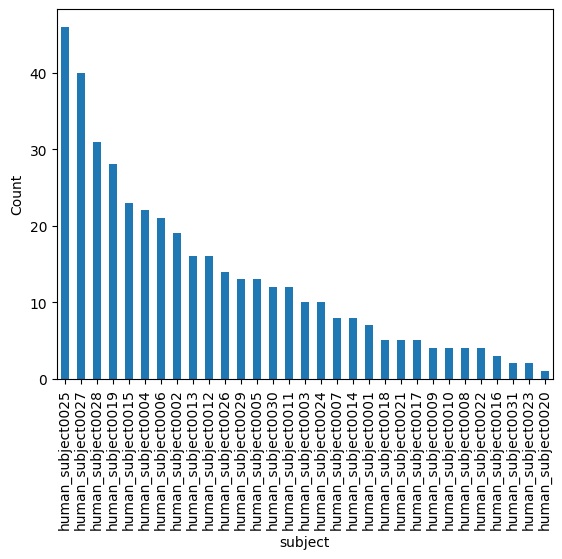

In [6]:
dash['subject'].value_counts().plot.bar()

plt.ylabel('Count')

plt.show()

In [7]:
dash.value_counts('epitope')

epitope
M1      249
BMLF     92
pp65     67
Name: count, dtype: int64

In [8]:
epitope_info = pd.DataFrame(
    columns=['name', 'species', 'mhc', 'peptide_seq', 'virus'],
    data=[
        ['BMLF', 'human', 'HLA-A*02:01', 'GLCTLVAML', 'EBV'],
        ['M1', 'human', 'HLA-A*02:01', 'GILGFVFTL', 'IAV'],
        ['pp65', 'human', 'HLA-A*02:01', 'NLVPMVATV', 'CMV'],
    ],
)

epitope_info.set_index('name')

,species,mhc,peptide_seq,virus
name,,,,
BMLF,human,HLA-A*02:01,GLCTLVAML,EBV
M1,human,HLA-A*02:01,GILGFVFTL,IAV
pp65,human,HLA-A*02:01,NLVPMVATV,CMV


In [9]:
sequences_with_negatives = pd.read_csv('../data/interim/sequences_dash_with_negatives.csv')

sequences_with_negatives = sequences_with_negatives.merge(dash, how='left', on='id')

sequences_with_negatives.loc[sequences_with_negatives['subject'].isna(), 'subject'] = 'Background'
sequences_with_negatives.loc[sequences_with_negatives['epitope'].isna(), 'epitope'] = 'Background'

In [10]:
def get_cdr3(sequence: str) -> str:
    numbering, _ = anarci.number(sequence)
    cdr3 = ''.join(amino_acid for (seq_id, _), amino_acid in numbering if amino_acid != '-' and seq_id in IMGT_CDR3)
    return tidytcells.junction.standardise(cdr3)


sequences_with_negatives['cdr3_alpha'] = sequences_with_negatives['tcr_alpha_chain'].apply(get_cdr3)
sequences_with_negatives['cdr3_beta'] = sequences_with_negatives['tcr_beta_chain'].apply(get_cdr3)

In [11]:
sequences_with_negatives = sequences_with_negatives.merge(
    epitope_info[['name', 'mhc', 'peptide_seq', 'virus']], how='left', left_on='peptide', right_on='peptide_seq'
)

In [12]:
distance_matrix, cdr3_distance_matrix = calculate_distances(
    sequences_with_negatives['cdr3_alpha'].tolist(), sequences_with_negatives['cdr3_beta'].tolist()
)

In [13]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [14]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [15]:
clusters_filtered = np.array(
    [str(cluster) if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else 'None' for cluster in clusters]
)

In [16]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [17]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [18]:
unique_subjects = sorted(sequences_with_negatives['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array(
    [[subject_to_colour[subject]] for subject in sequences_with_negatives['subject'].to_numpy()[new_order]]
)

In [19]:
unique_epitopes = sorted(sequences_with_negatives['epitope'].unique())
epitope_to_colour = {epitope: palette[i % num_colours] for i, epitope in enumerate(unique_epitopes)}
epitope_colours = np.array(
    [[epitope_to_colour[epitope]] for epitope in sequences_with_negatives['epitope'].to_numpy()[new_order]]
)

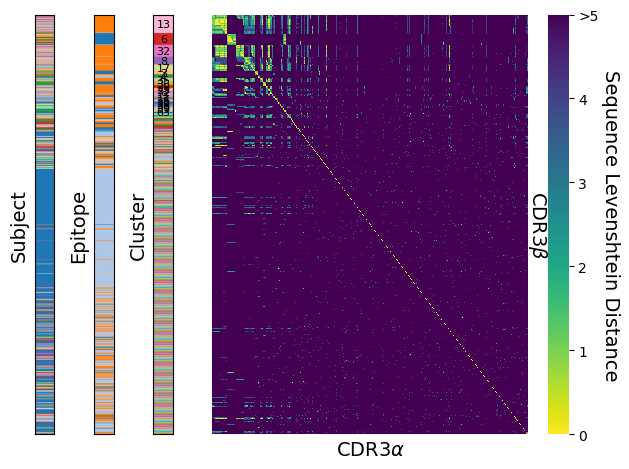

In [20]:
plot_sequence_distances(
    distance_matrix, cluster_colours, cluster_order, cluster_counts, new_order, subject_colours, epitope_colours
)
plt.show()

In [21]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

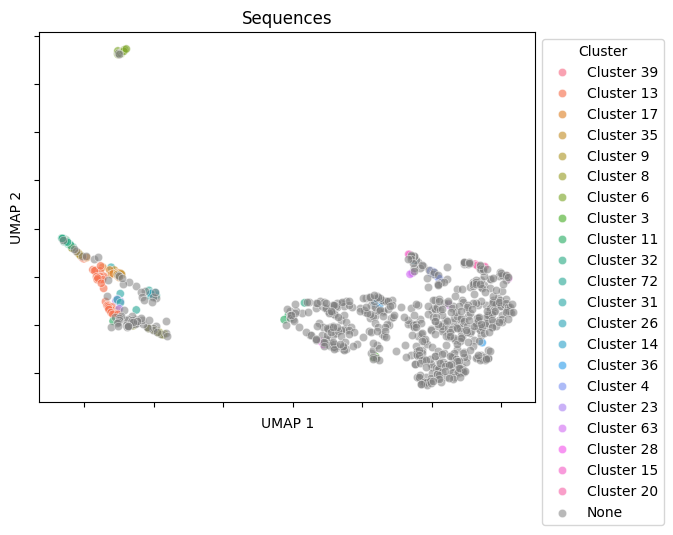

In [22]:
ax = plot_umap(sequence_umap, pd.Series(clusters_filtered), title='Sequences')
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1))

plt.show()

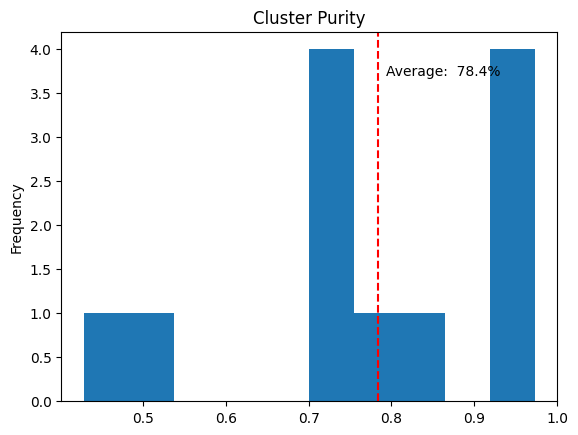

In [23]:
cluster_purities = (
    sequences_with_negatives.groupby(clusters_filtered)['epitope']
    .value_counts(normalize=True)
    .reset_index()
    .groupby('level_0')
    .filter(lambda group: group['epitope'].nunique() > 1 and 'Background' not in group['epitope'])  # noqa: PD101
    .groupby('level_0')
    .agg({'proportion': 'max'})
    .reset_index()
    .query("level_0 != 'None'")
)

cluster_purities['proportion'].plot.hist()

purity_mean = cluster_purities['proportion'].mean()
plt.axvline(purity_mean, color='red', linestyle='dashed')
plt.text(purity_mean + 0.01, plt.ylim()[1] - 0.5, f'Average: {purity_mean * 100: .1f}%')

plt.title('Cluster Purity')

plt.show()

## M1 Epitope Analysis

In [24]:
dash_m1 = dash.query("epitope == 'M1'").copy()

In [25]:
distance_matrix, cdr3_distance_matrix = calculate_distances(
    dash_m1['cdr3_a_aa'].tolist(), dash_m1['cdr3_b_aa'].tolist()
)

In [26]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [27]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [28]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [29]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [30]:
unique_subjects = sorted(dash_m1['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array([[subject_to_colour[subject]] for subject in dash_m1['subject'].to_numpy()[new_order]])

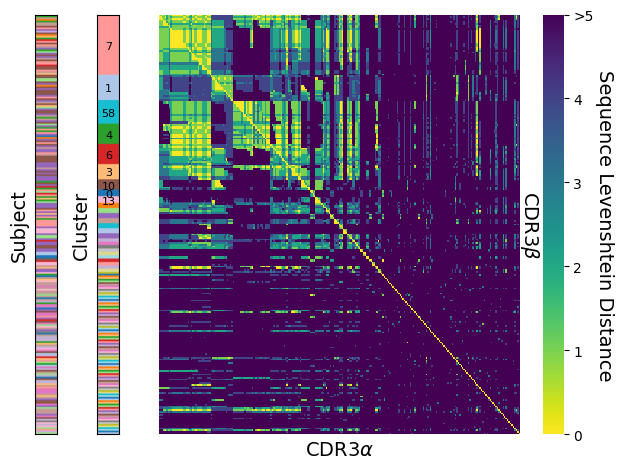

In [31]:
plot_sequence_distances(distance_matrix, cluster_colours, cluster_order, cluster_counts, new_order, subject_colours)
plt.show()

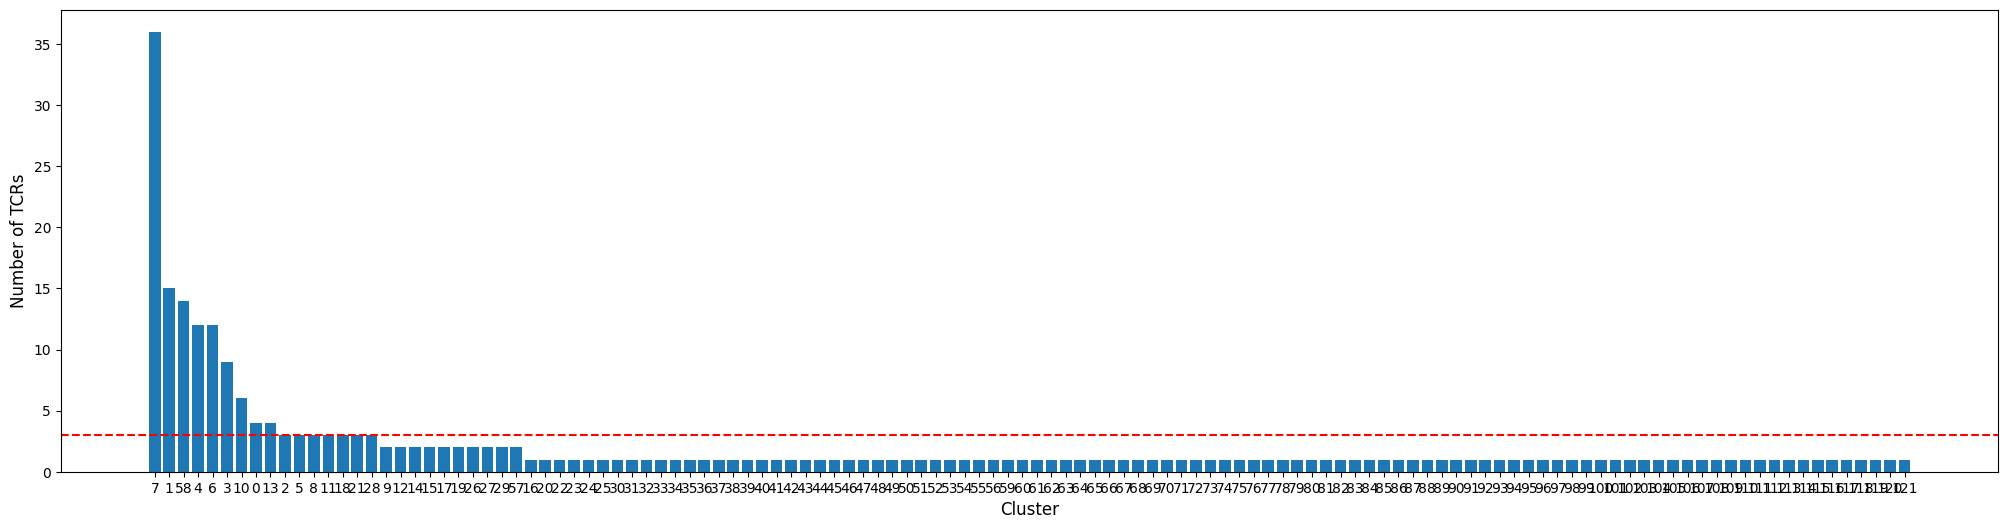

In [32]:
plt.figure(figsize=(25, 6))
plt.bar([str(cluster) for cluster in cluster_order], [cluster_counts[cluster] for cluster in cluster_order])

plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of TCRs', fontsize=12)
plt.axhline(MIN_CLUSTER_SIZE - 1, color='red', linestyle='--')

plt.show()

In [33]:
clusters_filtered = np.array([cluster if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else -1 for cluster in clusters])

In [34]:
dash_m1['cluster'] = clusters_filtered
dash_m1['cluster'] = dash_m1['cluster'].astype(str)
dash_m1['cluster'] = dash_m1['cluster'].replace('-1', 'None')

""


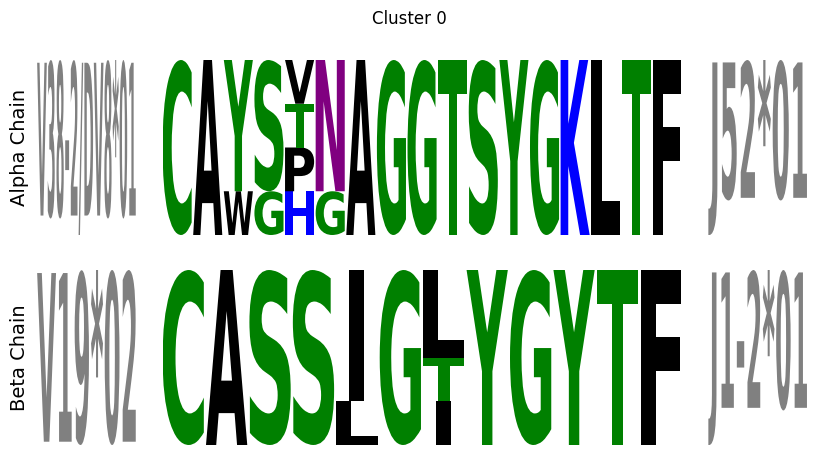

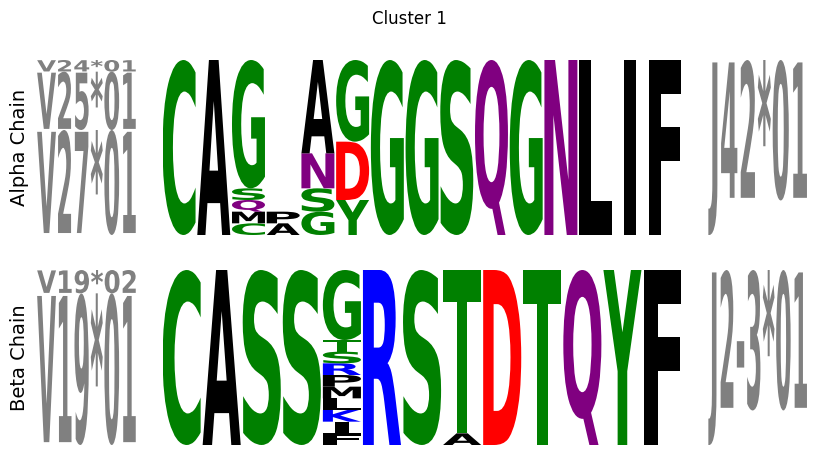

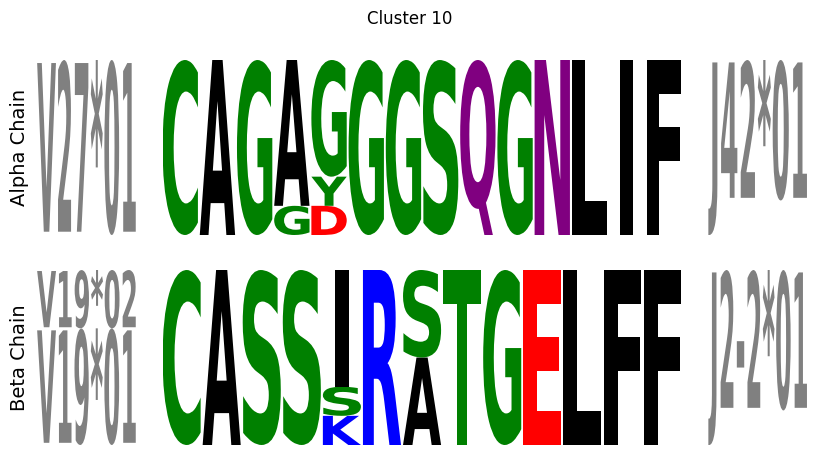

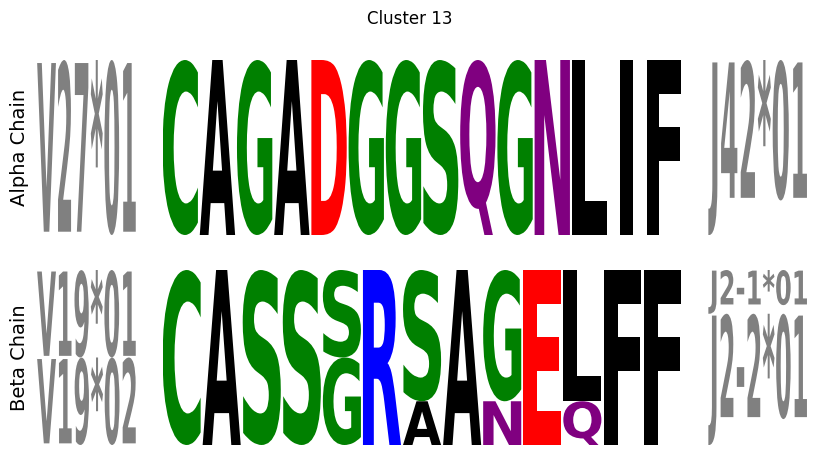

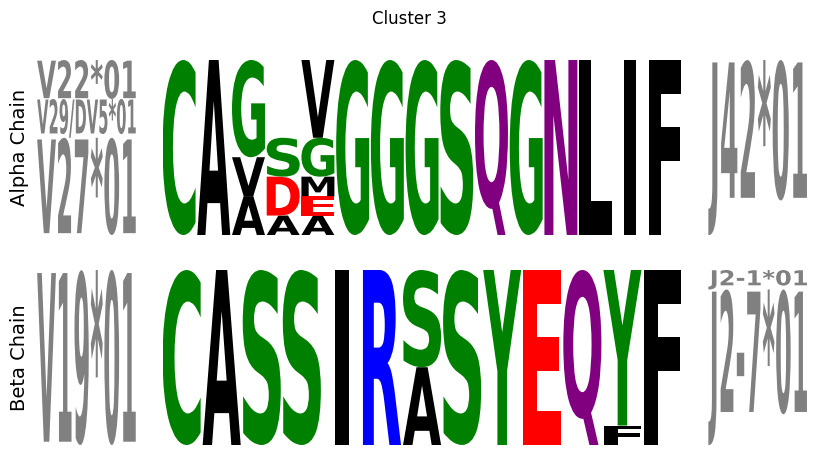

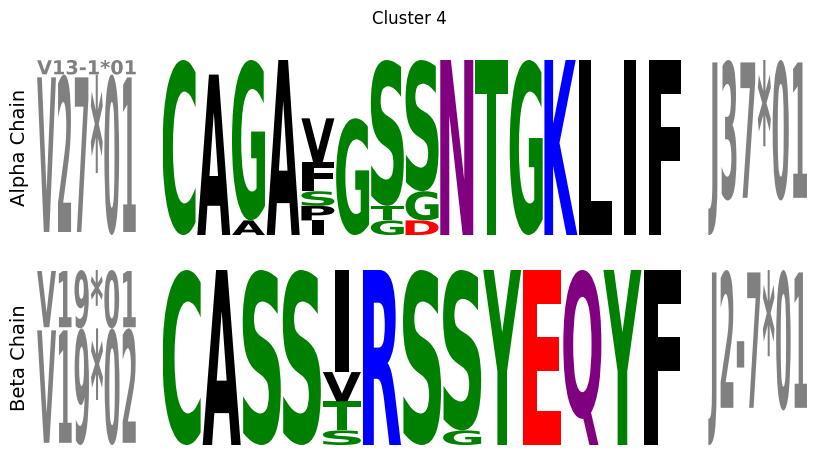

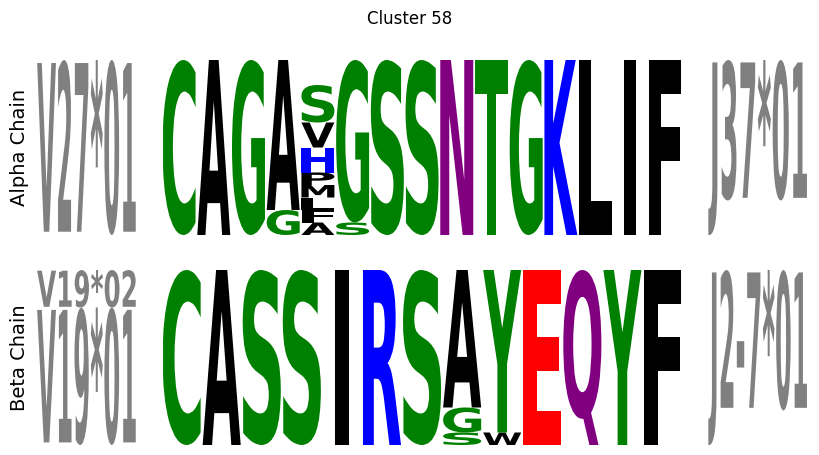

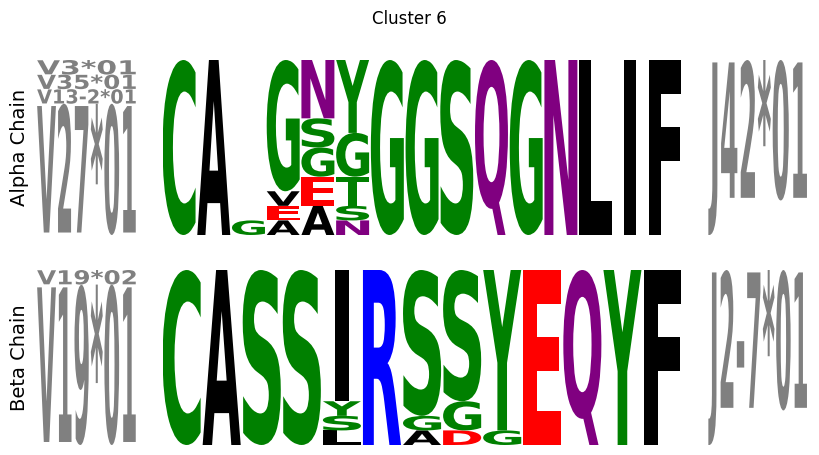

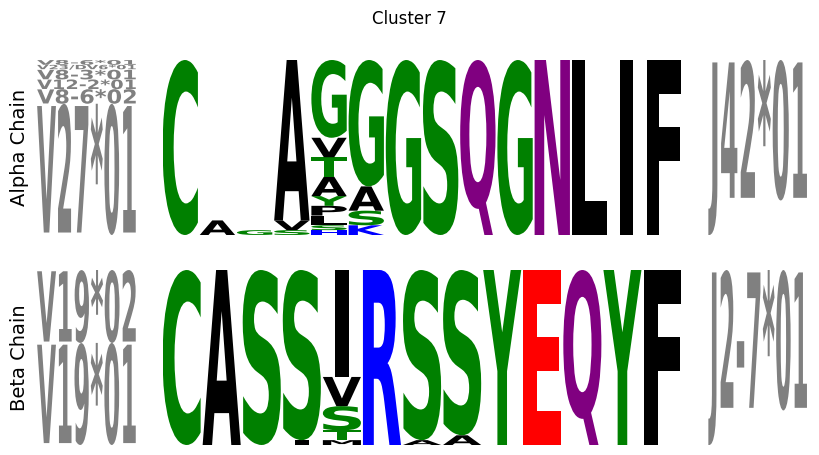

In [35]:
dash_m1.query("cluster != 'None'").groupby('cluster').apply(make_logo_plot, include_groups=False)

In [36]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

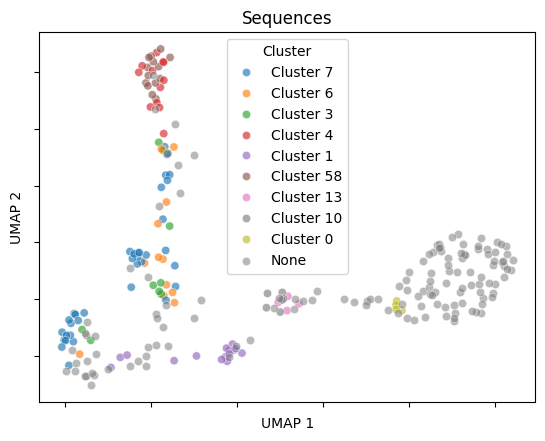

In [37]:
plot_umap(sequence_umap, dash_m1['cluster'], title='Sequences')
plt.show()

In [38]:
sequences_with_negatives_m1 = sequences_with_negatives.query("name == 'M1'")

In [39]:
sequences_with_negatives_m1.merge(dash_m1[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_m1 = sequences_with_negatives_m1.merge(dash_m1[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_m1['cluster'] = sequences_with_negatives_m1['cluster'].fillna('Background')

In [40]:
distance_matrix, cdr3_distance_matrix = calculate_distances(
    sequences_with_negatives_m1['cdr3_alpha'].tolist(), sequences_with_negatives_m1['cdr3_beta'].tolist()
)

In [41]:
sequence_umap_with_background = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

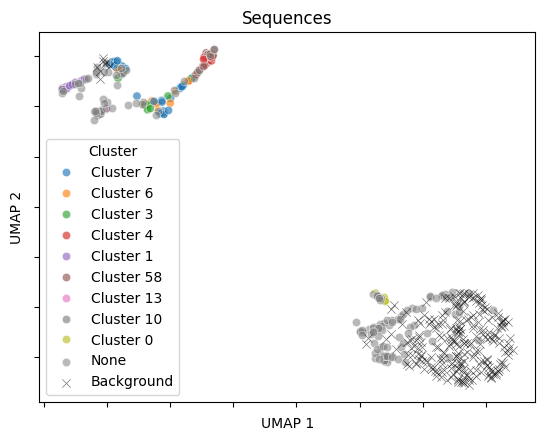

In [42]:
plot_umap(sequence_umap_with_background, sequences_with_negatives_m1['cluster'], title='Sequences')
plt.show()

## BMLF Epitope Analysis

In [43]:
dash_bmlf = dash.query("epitope == 'BMLF'").copy()

In [44]:
distance_matrix, cdr3_distance_matrix = calculate_distances(
    dash_bmlf['cdr3_a_aa'].tolist(), dash_bmlf['cdr3_b_aa'].tolist()
)

In [45]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [46]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [47]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [48]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [49]:
unique_subjects = sorted(dash_bmlf['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array([[subject_to_colour[subject]] for subject in dash_bmlf['subject'].to_numpy()[new_order]])

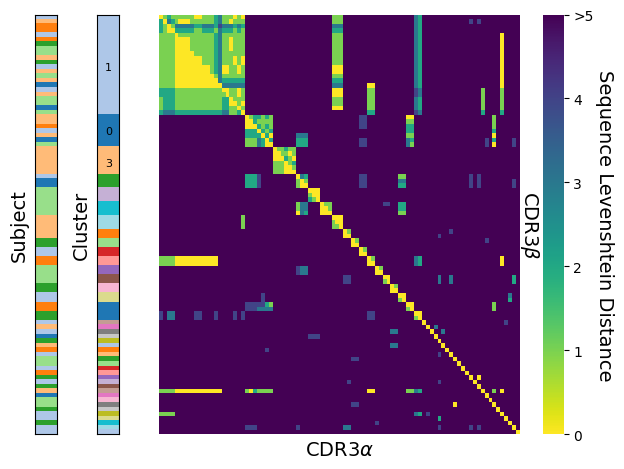

In [50]:
plot_sequence_distances(distance_matrix, cluster_colours, cluster_order, cluster_counts, new_order, subject_colours)
plt.show()

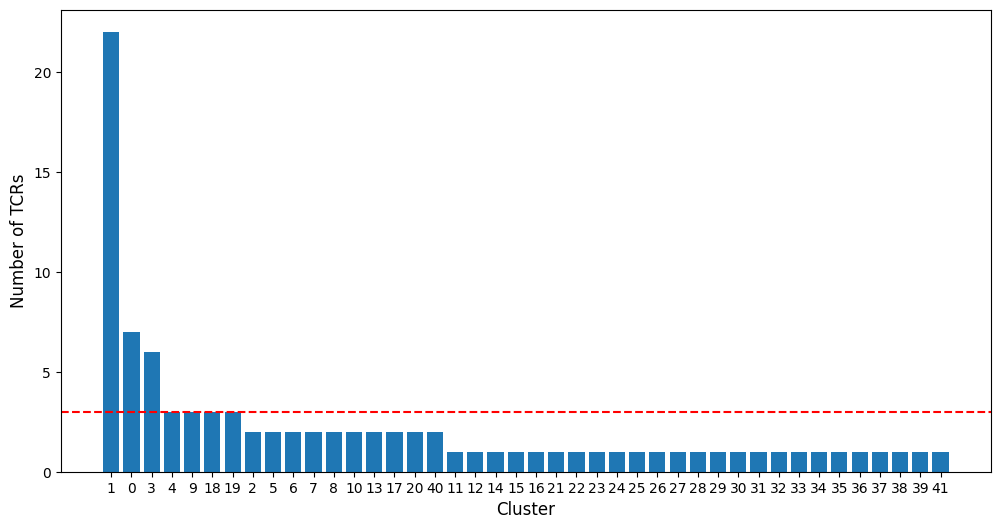

In [51]:
plt.figure(figsize=(12, 6))
plt.bar([str(cluster) for cluster in cluster_order], [cluster_counts[cluster] for cluster in cluster_order])

plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of TCRs', fontsize=12)
plt.axhline(MIN_CLUSTER_SIZE - 1, color='red', linestyle='--')

plt.show()

In [52]:
clusters_filtered = [cluster if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else -1 for cluster in clusters]

In [53]:
dash_bmlf['cluster'] = clusters_filtered
dash_bmlf['cluster'] = dash_bmlf['cluster'].astype(str)
dash_bmlf['cluster'] = dash_bmlf['cluster'].replace('-1', 'None')

""


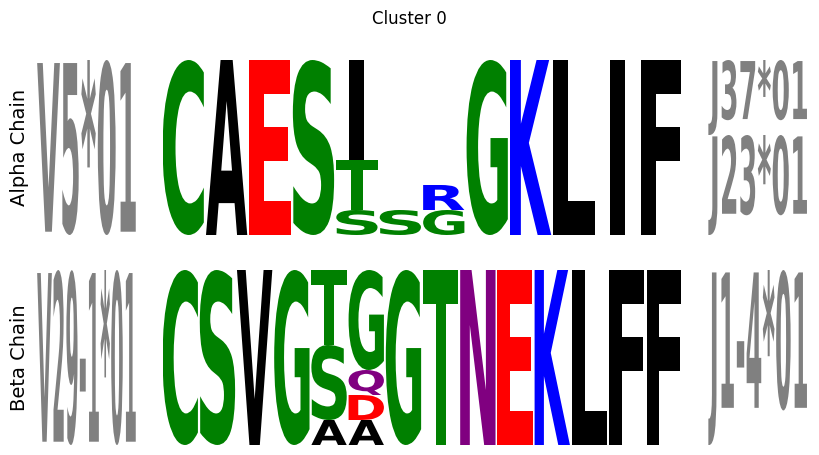

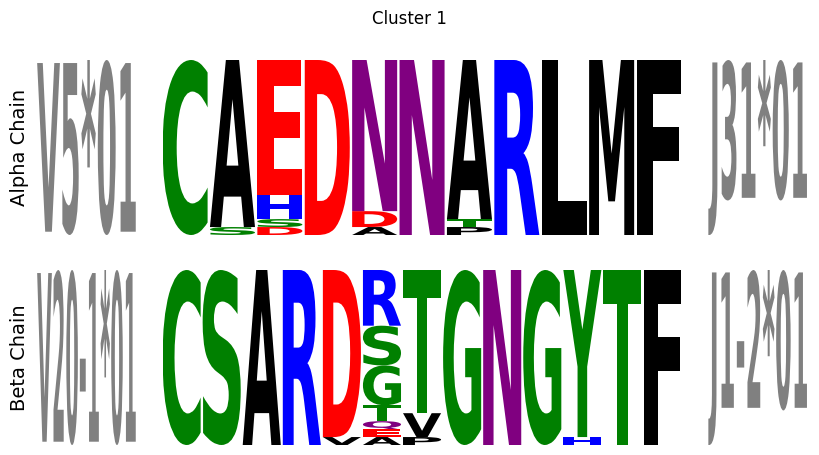

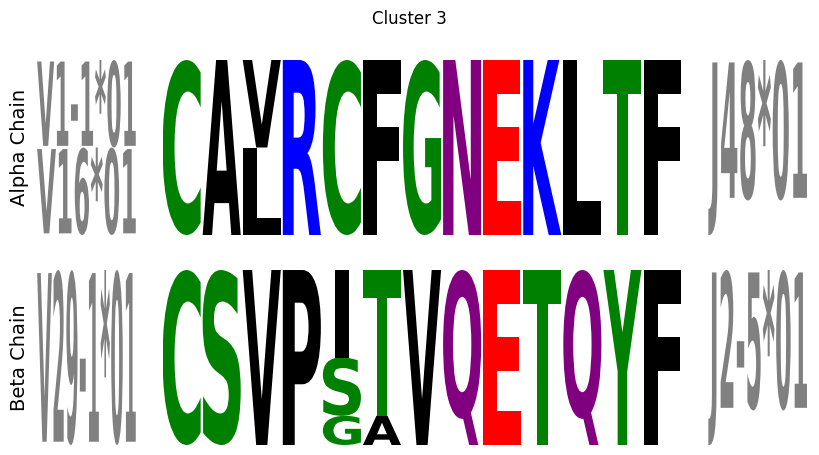

In [54]:
dash_bmlf.query("cluster != 'None'").groupby('cluster').apply(make_logo_plot, include_groups=False)

In [55]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

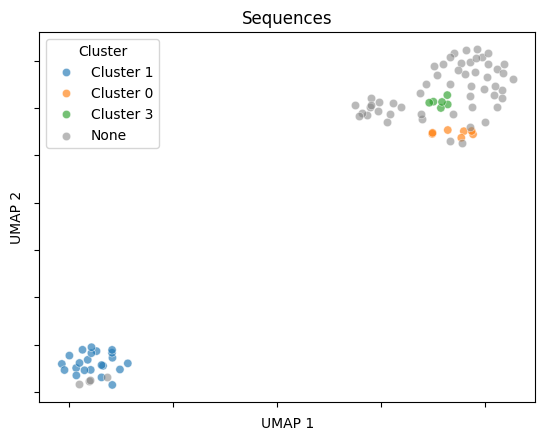

In [56]:
plot_umap(sequence_umap, dash_bmlf['cluster'], title='Sequences')
plt.show()

In [57]:
sequences_with_negatives_bmlf = sequences_with_negatives.query("name == 'BMLF'")

In [58]:
sequences_with_negatives_bmlf.merge(dash_bmlf[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_bmlf = sequences_with_negatives_bmlf.merge(dash_bmlf[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_bmlf['cluster'] = sequences_with_negatives_bmlf['cluster'].fillna('Background')

In [59]:
distance_matrix, cdr3_distance_matrix = calculate_distances(
    sequences_with_negatives_bmlf['cdr3_alpha'].tolist(), sequences_with_negatives_bmlf['cdr3_beta'].tolist()
)

In [60]:
sequence_umap_with_background = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

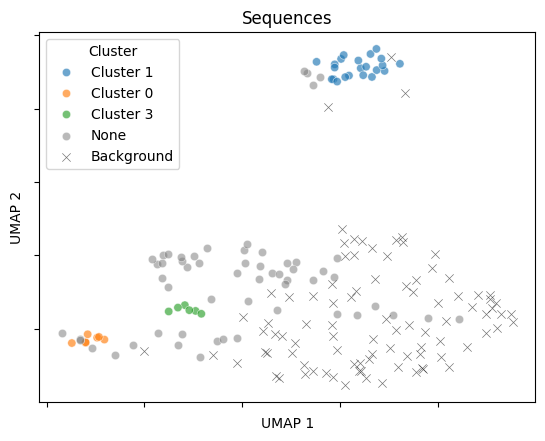

In [61]:
plot_umap(sequence_umap_with_background, sequences_with_negatives_bmlf['cluster'], title='Sequences')
plt.show()

### Structure Prediction Features

In [62]:
def is_constant(column: pd.Series) -> bool:
    return (column == column.iloc[0]).all()


def drop_constant_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    return df[[column_name for column_name in df.columns if not is_constant(df[column_name])]]

#### Confidence Scores

In [63]:
confidence_scores = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_dash_bmlf.csv')
confidence_scores['top_rank'] = False
confidence_scores.loc[confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

In [64]:
confidence_scores = confidence_scores.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)

In [65]:
confidence_scores = confidence_scores.merge(dash_bmlf, how='left', left_on='name', right_on='id')
confidence_scores['cluster'] = confidence_scores['cluster'].fillna('Background')

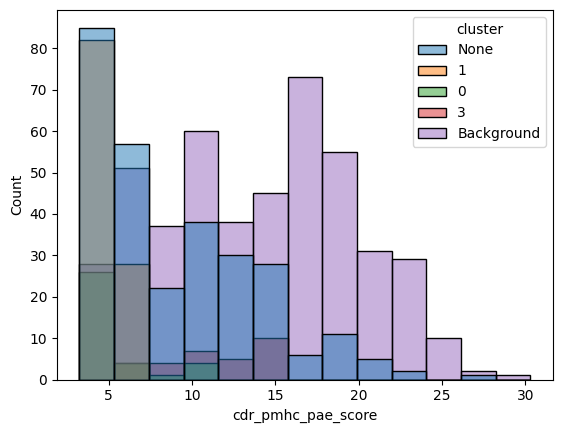

In [66]:
sns.histplot(confidence_scores, x='cdr_pmhc_pae_score', hue='cluster')

plt.show()

In [67]:
confidence_scores_values = confidence_scores.select_dtypes('number')
confidence_scores_values = confidence_scores_values[
    [column_name for column_name in confidence_scores_values.columns if column_name not in ('count', 'sample', 'seed')]
]

confidence_scores_values = drop_constant_columns(confidence_scores_values)
confidence_scores_values = confidence_scores_values.to_numpy()

In [68]:
confidence_scores_values_norm = StandardScaler().fit_transform(confidence_scores_values)
confidence_scores_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(confidence_scores_values_norm)

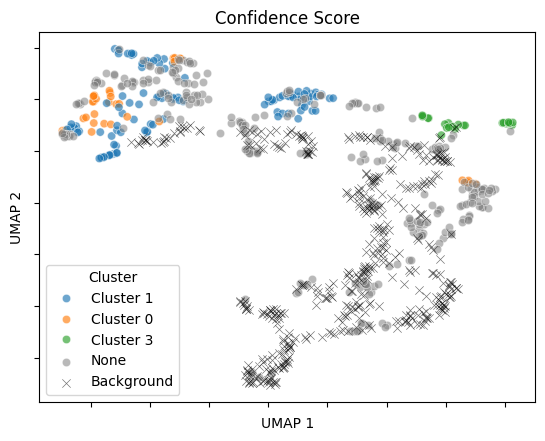

In [69]:
plot_umap(confidence_scores_umap, confidence_scores['cluster'].to_numpy(), title='Confidence Score')
plt.show()

#### Structural Features

In [70]:
structure_features = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_structural_features_dash_bmlf.csv')

In [71]:
structure_features = structure_features.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)

In [72]:
structure_features = structure_features.merge(dash_bmlf, how='outer', left_on='name', right_on='id')
structure_features['cluster'] = structure_features['cluster'].fillna('Background')

In [73]:
structure_features_values = structure_features.select_dtypes('number')
structure_features_values = structure_features_values[
    [
        column_name
        for column_name in structure_features_values.columns
        if column_name not in ('count', 'sample', 'seed', 'label')
    ]
]

structure_features_values = drop_constant_columns(structure_features_values)
structure_features_values = structure_features_values.dropna()

selected_stucture_features = structure_features_values.index

structure_features_values = structure_features_values.to_numpy()

In [74]:
structure_features_values_norm = StandardScaler().fit_transform(structure_features_values)
structure_features_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(structure_features_values_norm)

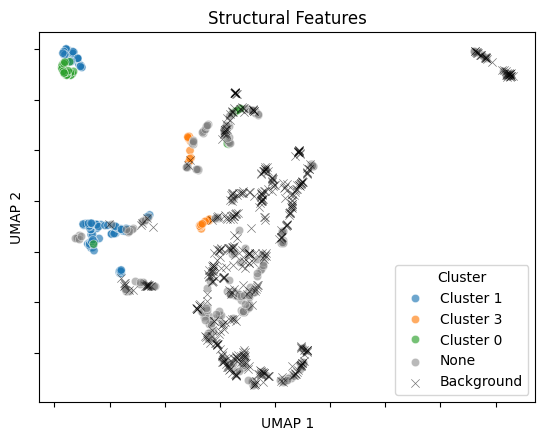

In [75]:
plot_umap(
    structure_features_umap,
    structure_features.loc[selected_stucture_features, 'cluster'].to_numpy(),
    title='Structural Features',
)
plt.show()

##### Contact Maps

In [76]:
contact_maps = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_contact_maps_dash_bmlf.csv')

In [77]:
contact_maps['relative_pos_centre_tcr'] = contact_maps['relative_pos_centre_tcr'].astype(int)

In [78]:
contact_maps['resi_pmhc'] = contact_maps['resi_pmhc'].astype(str).str.replace('.0', '')

In [79]:
contact_maps['chain_type_pmhc'].unique()

array(['antigen_chain', 'mhc_chain1'], dtype=object)

In [80]:
contact_maps_antigens = contact_maps[contact_maps['chain_type_pmhc'] == 'antigen_chain'].copy()

In [81]:
contact_maps_antigens['relative_pos_centre_pmhc'] = contact_maps_antigens['relative_pos_centre_pmhc'].astype(int)

In [82]:
contact_map_antigens_scores = (
    contact_maps_antigens.groupby(['name', 'seed', 'sample'])
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'])
    .reset_index()
    .pivot_table(
        index=['name', 'seed', 'sample'],
        columns=['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)
contact_map_antigens_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in contact_map_antigens_scores.columns.to_flat_index()
]

In [83]:
contact_maps_mhc = contact_maps[contact_maps['chain_type_pmhc'] == 'mhc_chain1'].copy()

In [84]:
contact_map_mhc_scores = (
    contact_maps_mhc.groupby(['name', 'seed', 'sample'])
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'resi_pmhc'])
    .reset_index()
    .pivot_table(
        index=['name', 'seed', 'sample'],
        columns=['cdr_type', 'relative_pos_centre_tcr', 'resi_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)

contact_map_mhc_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in contact_map_mhc_scores.columns.to_flat_index()
]

In [85]:
contact_map_scores = pd.concat([contact_map_antigens_scores, contact_map_mhc_scores], axis=1).fillna(0).map(int)
contact_map_scores = drop_constant_columns(contact_map_scores)
contact_map_column_names = contact_map_scores.columns

contact_map_scores = contact_map_scores.reset_index()

In [86]:
contact_map_scores = contact_map_scores.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)

In [87]:
contact_map_scores = contact_map_scores.merge(dash_bmlf, how='outer', left_on='name', right_on='id')
contact_map_scores['cluster'] = contact_map_scores['cluster'].fillna('Background')

In [88]:
contact_map_scores_norm = StandardScaler().fit_transform(contact_map_scores[contact_map_column_names])

In [89]:
contact_map_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(contact_map_scores_norm)

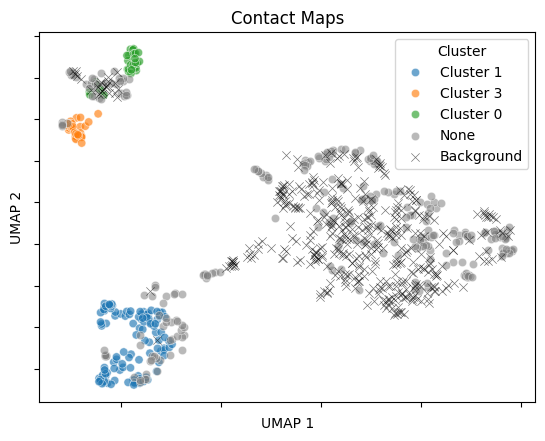

In [90]:
plot_umap(contact_map_umap, contact_map_scores['cluster'].to_numpy(), title='Contact Maps')
plt.show()

##### Interactions

In [91]:
interactions = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_interactions_dash_bmlf.csv')

In [92]:
interactions_scores = (
    interactions.groupby(['name', 'seed', 'sample'])['type']
    .value_counts()
    .reset_index()
    .pivot_table(index=['name', 'seed', 'sample'], columns='type', values='count')
    .fillna(0)
    .map(int)
)
interactions_scores_column_names = interactions_scores.columns

interactions_scores = interactions_scores.reset_index()

In [93]:
interactions_scores = interactions_scores.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)

In [94]:
interactions_scores = interactions_scores.merge(dash_bmlf, how='outer', left_on='name', right_on='id')
interactions_scores['cluster'] = interactions_scores['cluster'].fillna('Background')
interactions_scores[interactions_scores_column_names] = interactions_scores[interactions_scores_column_names].fillna(0)

In [95]:
interactions_scores_norm = StandardScaler().fit_transform(interactions_scores[interactions_scores_column_names])

In [96]:
interactions_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(interactions_scores_norm)

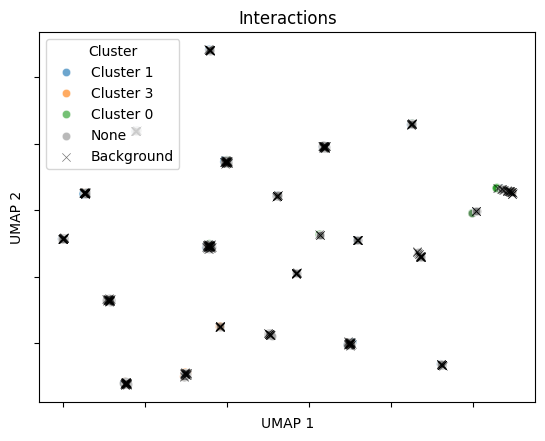

In [97]:
plot_umap(interactions_umap, interactions_scores['cluster'].to_numpy(), title='Interactions')
plt.show()

##### Combined

In [98]:
combined_scores = (
    structure_features.merge(contact_map_scores, how='inner').merge(interactions_scores, how='inner').fillna(0.0)
)

In [99]:
combined_scores_values = combined_scores.select_dtypes('number')
combined_scores_values = combined_scores_values[
    [
        column_name
        for column_name in combined_scores_values.columns
        if column_name not in ('count', 'sample', 'seed', 'label')
    ]
]
combined_scores_values = combined_scores_values.to_numpy()

In [100]:
combined_scores_values_norm = StandardScaler().fit_transform(combined_scores_values)

In [101]:
combined_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(combined_scores_values_norm)

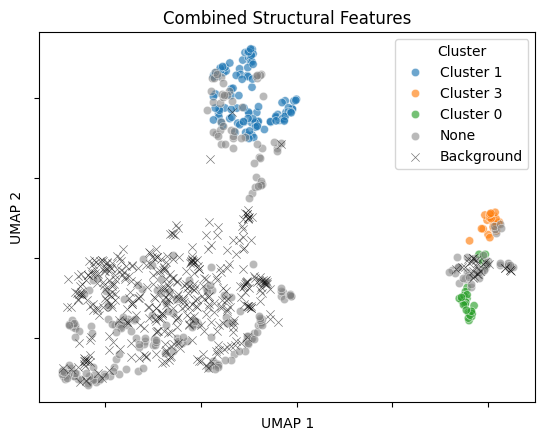

In [102]:
plot_umap(combined_umap, combined_scores['cluster'].to_numpy(), title='Combined Structural Features')
plt.show()

Reversing the structural clusters to the sequence space

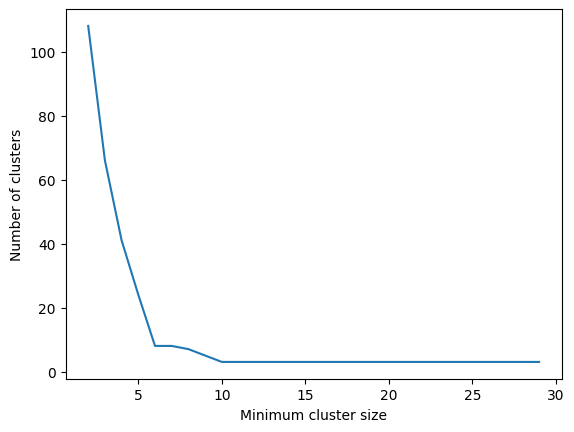

In [103]:
min_cluster_sizes = list(range(2, 30))
num_clusters = []
for min_cluster_size in min_cluster_sizes:
    structural_clusters = HDBSCAN(min_cluster_size=min_cluster_size).fit_predict(
        combined_scores_values_norm[combined_scores['label'].astype(bool)]
    )
    num_clusters.append(len(np.unique(structural_clusters[structural_clusters != -1])))

plt.plot(min_cluster_sizes, num_clusters)

plt.xlabel('Minimum cluster size')
plt.ylabel('Number of clusters')

plt.show()

In [104]:
structural_clusters = (
    HDBSCAN(min_cluster_size=6)
    .fit_predict(combined_scores_values_norm[combined_scores['label'].astype(bool)])
    .astype(str)
)
structural_clusters[structural_clusters == '-1'] = 'None'

combined_scores['structural_cluster'] = 'Background'
combined_scores.loc[combined_scores['label'].astype(bool), 'structural_cluster'] = structural_clusters

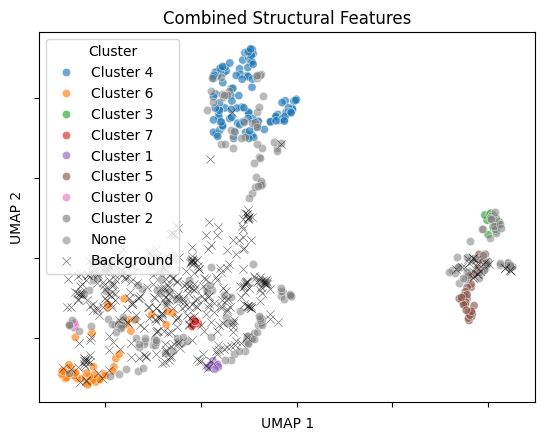

In [105]:
plot_umap(combined_umap, combined_scores['structural_cluster'].to_numpy(), title='Combined Structural Features')
plt.show()

In [106]:
agg_structural_clusters = (
    combined_scores[combined_scores['label'].astype(bool)].groupby('name')['structural_cluster'].apply(list)
)

In [107]:
def count_clusters(clusters: list) -> dict[str, int]:
    count = {}
    for cluster in clusters:
        if cluster not in count:
            count[cluster] = 1

        else:
            count[cluster] += 1

    return count


agg_structural_clusters = agg_structural_clusters.apply(count_clusters)

In [108]:
def get_consensus(cluster_counts: dict) -> str:
    """Get the consensus clustuer from the counts.

    Note: does not handle ties.

    """
    max_count = 0
    consensus_cluster = None

    for cluster, count in cluster_counts.items():
        if count > max_count:
            consensus_cluster = cluster
            max_count = count

    return consensus_cluster


agg_structural_clusters = agg_structural_clusters.apply(get_consensus)

In [109]:
dash_bmlf = dash_bmlf.merge(agg_structural_clusters.to_frame(), how='left', left_on='id', right_index=True)

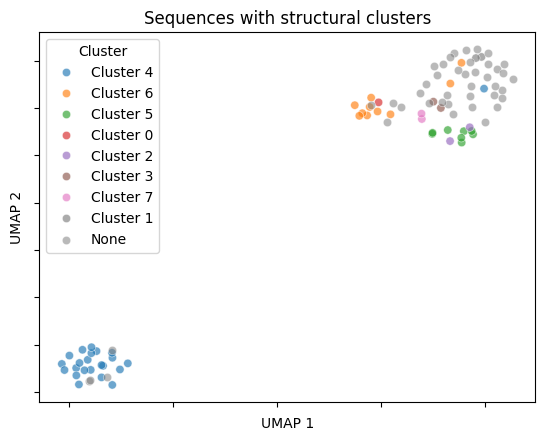

In [110]:
plot_umap(sequence_umap, dash_bmlf['structural_cluster'], title='Sequences with structural clusters')
plt.show()

## pp65 Epitope Analysis

In [111]:
dash_pp65 = dash.query("epitope == 'pp65'").copy()

In [112]:
distance_matrix, cdr3_distance_matrix = calculate_distances(
    dash_pp65['cdr3_a_aa'].tolist(), dash_pp65['cdr3_b_aa'].tolist()
)

In [113]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [114]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [115]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [116]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [117]:
unique_subjects = sorted(dash_pp65['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array([[subject_to_colour[subject]] for subject in dash_pp65['subject'].to_numpy()[new_order]])

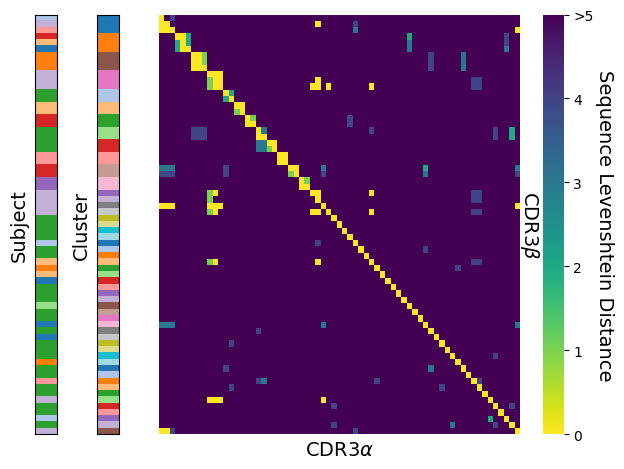

In [118]:
plot_sequence_distances(distance_matrix, cluster_colours, cluster_order, cluster_counts, new_order, subject_colours)
plt.show()

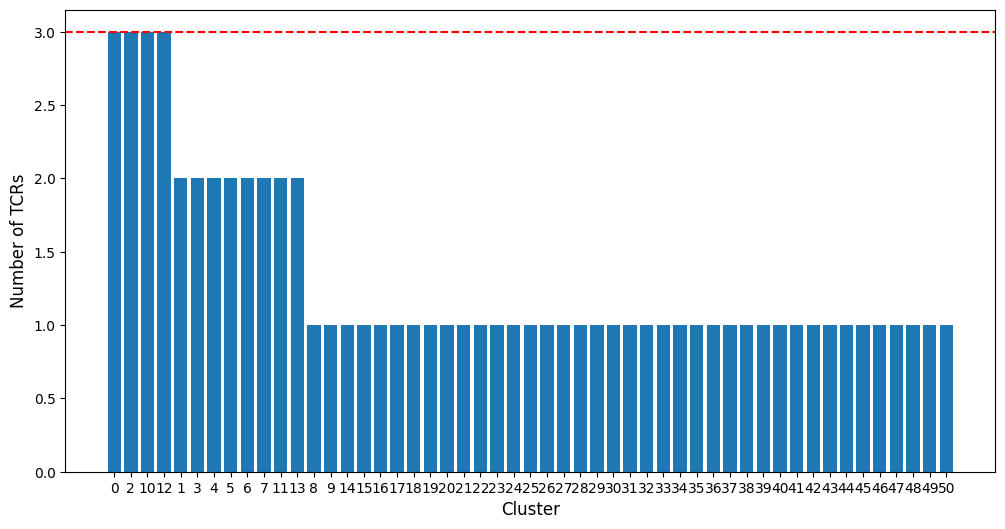

In [119]:
plt.figure(figsize=(12, 6))
plt.bar([str(cluster) for cluster in cluster_order], [cluster_counts[cluster] for cluster in cluster_order])

plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of TCRs', fontsize=12)
plt.axhline(MIN_CLUSTER_SIZE - 1, color='red', linestyle='--')

plt.show()

In [120]:
clusters_filtered = [cluster if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else -1 for cluster in clusters]

In [121]:
dash_pp65['cluster'] = clusters_filtered
dash_pp65['cluster'] = dash_pp65['cluster'].astype(str)
dash_pp65['cluster'] = dash_pp65['cluster'].replace('-1', 'None')

In [122]:
dash_pp65.query("cluster != 'None'").groupby('cluster').apply(make_logo_plot, include_groups=False)

,id,subject,epitope,count,v_a_gene,j_a_gene,cdr3_a_aa,v_b_gene,j_b_gene,cdr3_b_aa,clone_id
cluster,,,,,,,,,,,


In [123]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

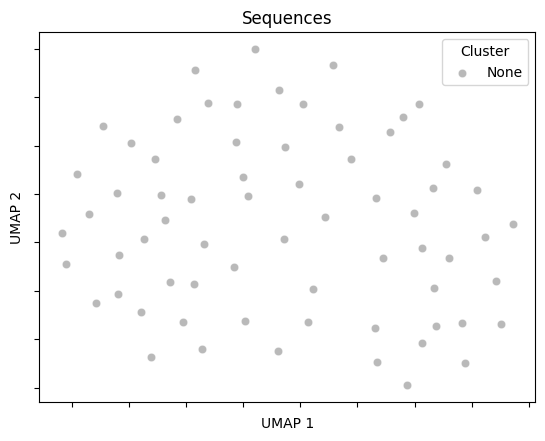

In [124]:
plot_umap(sequence_umap, dash_pp65['cluster'], title='Sequences')
plt.show()

In [125]:
sequences_with_negatives_pp65 = sequences_with_negatives.query("name == 'pp65'")

In [126]:
sequences_with_negatives_pp65.merge(dash_pp65[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_pp65 = sequences_with_negatives_pp65.merge(dash_pp65[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_pp65['cluster'] = sequences_with_negatives_pp65['cluster'].fillna('Background')

In [127]:
distance_matrix, cdr3_distance_matrix = calculate_distances(
    sequences_with_negatives_pp65['cdr3_alpha'].tolist(), sequences_with_negatives_pp65['cdr3_beta'].tolist()
)

In [128]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

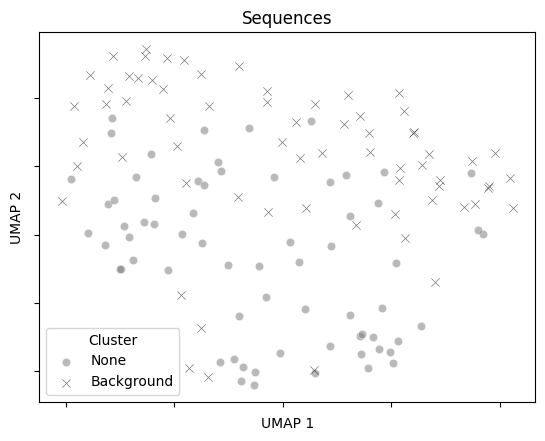

In [129]:
plot_umap(sequence_umap, sequences_with_negatives_pp65['cluster'], title='Sequences')
plt.show()